# Signature Forgery Detection — CEDAR

**Case study:** verify a questioned handwritten signature against genuine enrollment signatures. Compare **Geometric features + SVM**, **HOG + SVM**, and a **Siamese CNN** on unseen writers.

This notebook contains the complete experiment, EDA, training, plots and measured results. Run cells in order. Genuine = 1, forged = 0; larger scores mean more genuine. Scores are not calibrated probabilities.

**Protocol:** 33 training / 8 validation / 14 test writers (seed 0). Six genuine enrollment signatures per writer; remaining 18 genuine and all 24 skilled forgeries are questions. Average six reference scores per question. Models and thresholds are selected on validation writers only. The historical table used random signature pairs, so its accuracy is not directly comparable.

**Runtime:** Python 3.13, CPU supported; CNN may take several minutes. Install requirements first. Set RETRAIN=True only to run a new experiment; existing checkpoints can be loaded for figures.


In [1]:
from pathlib import Path
import copy, hashlib, json, os, platform, random, time
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd()/".runtime"/"matplotlib"))
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from sklearn import metrics
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier
import joblib
from IPython.display import display

torch.set_num_threads(min(4, os.cpu_count() or 1))
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def check_scores(y, score):
    y, score = np.asarray(y, dtype=int), np.asarray(score, dtype=float)
    if y.ndim != 1 or score.shape != y.shape or not np.isfinite(score).all():
        raise ValueError('Labels and finite scores must be matching 1D arrays')
    if set(np.unique(y)) != {0, 1}:
        raise ValueError('Both genuine=1 and forged=0 labels are required')
    return y, score

def select_threshold(y, score):
    y, score = check_scores(y, score)
    far, gar, thresholds = metrics.roc_curve(y, score, drop_intermediate=False)
    frr = 1 - gar
    best = np.lexsort(((far + frr) / 2, np.abs(far - frr)))[0]
    t = thresholds[best]
    return float(t if np.isfinite(t) else np.nextafter(score.max(), np.inf))

def descriptive_eer(y, score):
    far, gar, _ = metrics.roc_curve(y, score, drop_intermediate=False)
    frr = 1 - gar
    k = np.flatnonzero(far >= frr)[0]
    if k == 0: return float((far[0] + frr[0]) / 2)
    gap0, gap1 = far[k-1] - frr[k-1], far[k] - frr[k]
    weight = -gap0 / (gap1-gap0) if gap1 != gap0 else 0
    return float(far[k-1] + weight * (far[k]-far[k-1]))

def evaluate(y, score, threshold):
    y, score = check_scores(y, score)
    pred = (score >= threshold).astype(int)
    tn, fp, fn, tp = metrics.confusion_matrix(y, pred, labels=[0,1]).ravel()
    far, frr = fp/(tn+fp), fn/(fn+tp)
    return dict(accuracy=metrics.accuracy_score(y,pred),
        balanced_accuracy=metrics.balanced_accuracy_score(y,pred),
        genuine_precision=metrics.precision_score(y,pred,zero_division=0),
        genuine_recall=metrics.recall_score(y,pred,zero_division=0),
        genuine_F1=metrics.f1_score(y,pred,zero_division=0),
        forged_precision=metrics.precision_score(y,pred,pos_label=0,zero_division=0),
        forged_recall=metrics.recall_score(y,pred,pos_label=0,zero_division=0),
        forged_F1=metrics.f1_score(y,pred,pos_label=0,zero_division=0),
        specificity=tn/(tn+fp), MCC=metrics.matthews_corrcoef(y,pred),
        ROC_AUC=metrics.roc_auc_score(y,score),
        genuine_AP=metrics.average_precision_score(y,score),
        forged_AP=metrics.average_precision_score(1-y,-score),
        FAR=far, FRR=frr, HTER=(far+frr)/2,
        ROC_EER=descriptive_eer(y,score), threshold=float(threshold),
        TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp),n_queries=len(y))

def enrollment_protocol(manifest, seed=0, n_refs=6):
    if manifest.path.duplicated().any() or manifest.sha256.duplicated().any():
        raise ValueError('Duplicate image paths/content: resolve before splitting')
    out = manifest.copy().reset_index(drop=True)
    writers = sorted(out.writer.unique())
    if len(writers) < 10: raise ValueError('At least 10 writers required for three splits')
    rng = np.random.default_rng(seed); rng.shuffle(writers)
    a,b = int(.6*len(writers)), int(.75*len(writers))
    splits = {w:s for ws,s in [(writers[:a],'train'),(writers[a:b],'val'),(writers[b:],'test')] for w in ws}
    out['split'] = out.writer.map(splits); out['role'] = 'query'
    for w in writers:
        genuine = out.index[(out.writer == w)&(out.label == 1)].to_numpy()
        if len(genuine) <= n_refs or not ((out.writer == w)&(out.label == 0)).any():
            raise ValueError(f'Insufficient enrollment/query data for writer {w}')
        out.loc[rng.choice(genuine,n_refs,replace=False),'role'] = 'enrollment'
    return out

def make_pair_table(manifest, split):
    rows=[]
    for w,d in manifest[manifest.split==split].groupby('writer',sort=True):
        refs=d[d.role=='enrollment'].sort_values('path')
        for q in d[d.role=='query'].itertuples():
            for r in refs.itertuples():
                rows.append(dict(writer=w,query=q.path,reference=r.path,label=q.label,qi=q.image_id,ri=r.image_id))
    return pd.DataFrame(rows)

def aggregate_scores(pairs, scores):
    scores=np.asarray(scores)
    if scores.shape != (len(pairs),) or not np.isfinite(scores).all():
        raise ValueError('One finite score per pair required')
    frame=pairs[['query','writer','label']].copy(); frame['score']=scores
    if (frame.groupby('query')[['writer','label']].nunique()>1).any().any():
        raise ValueError('Inconsistent writer/label for a query')
    return frame.groupby(['query','writer','label'],as_index=False,sort=True).score.mean()


## 1. Preprocessing and feature representations

Otsu segmentation locates ink, tiny isolated noise components are removed, and a crop is fitted to a 64×128 canvas **without stretching**. Grayscale ink intensities are retained within the mask. Blank images raise an error instead of silently becoming signatures. Geometry describes shape, moments, stroke density and spatial projections. HOG describes local edge directions.


In [2]:
H,W=64,128

def preprocess(image):
    if image is None or image.size == 0: raise ValueError('Unreadable/empty image')
    gray=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY) if image.ndim==3 else image.copy()
    if gray.ndim != 2 or gray.dtype != np.uint8: raise ValueError('Expected uint8 image')
    blur=cv2.GaussianBlur(gray,(3,3),0)
    _,mask=cv2.threshold(blur,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
    n,lab,stats,_=cv2.connectedComponentsWithStats(mask)
    if n<=1: raise ValueError('Blank signature image')
    keep=np.flatnonzero(stats[1:,cv2.CC_STAT_AREA]>=max(3,stats[1:,cv2.CC_STAT_AREA].max()*.001))+1
    mask=np.isin(lab,keep)
    yy,xx=np.nonzero(mask)
    if len(xx)<5: raise ValueError('No usable signature ink')
    ink=np.where(mask,255-gray,0).astype(np.uint8)
    ink=ink[yy.min():yy.max()+1,xx.min():xx.max()+1]
    scale=min((W-8)/ink.shape[1],(H-8)/ink.shape[0])
    ink=cv2.resize(ink,(max(1,round(ink.shape[1]*scale)),max(1,round(ink.shape[0]*scale))),interpolation=cv2.INTER_AREA)
    out=np.zeros((H,W),np.uint8); y=(H-ink.shape[0])//2; x=(W-ink.shape[1])//2
    out[y:y+ink.shape[0],x:x+ink.shape[1]]=ink
    return out

def geometric_features(image):
    mask=(image>40).astype(np.uint8); yy,xx=np.nonzero(mask)
    if len(xx)<2: raise ValueError('Insufficient ink for geometry')
    cnt,_=cv2.findContours(mask,cv2.RETR_LIST,cv2.CHAIN_APPROX_SIMPLE)
    pts=np.column_stack((xx,yy)).astype(np.int32).reshape(-1,1,2)
    x,y,w,h=cv2.boundingRect(pts)
    hull=max(cv2.contourArea(cv2.convexHull(pts)),1.)
    hu=cv2.HuMoments(cv2.moments(mask,binaryImage=True)).ravel()
    hu=-np.sign(hu)*np.log10(np.abs(hu)+1e-8)
    cov=np.cov(np.column_stack((xx/W,yy/H)),rowvar=False)
    eig=np.linalg.eigvalsh(cov)
    zones=cv2.resize(mask.astype(np.float32),(8,4),interpolation=cv2.INTER_AREA).ravel()
    cols=cv2.resize(mask.mean(0)[None].astype(np.float32),(32,1),interpolation=cv2.INTER_AREA).ravel()
    rows=cv2.resize(mask.mean(1)[None].astype(np.float32),(16,1),interpolation=cv2.INTER_AREA).ravel()
    # Density and stroke width capture shape; raw file size and writer IDs are excluded.
    dist=cv2.distanceTransform(mask,cv2.DIST_L2,3)
    basics=[w/max(h,1),mask.mean(),len(cnt)/50,len(xx)/hull,xx.mean()/W,yy.mean()/H,
            xx.std()/W,yy.std()/H,cov[0,1],eig[0]/max(eig[1],1e-8),
            sum(cv2.arcLength(c,True) for c in cnt)/(H+W),
            dist[mask>0].mean()/H,dist.max()/H]
    return np.concatenate((basics,hu,zones,cols,rows)).astype(np.float32)

HOG=cv2.HOGDescriptor((W,H),(16,16),(8,8),(8,8),9)

def pair_features(features,pairs,relative=False):
    a=features[pairs.ri.to_numpy()]; b=features[pairs.qi.to_numpy()]
    diff=np.abs(a-b)
    cosine=(a*b).sum(1)/(np.linalg.norm(a,axis=1)*np.linalg.norm(b,axis=1)+1e-8)
    extra=np.column_stack((cosine,np.linalg.norm(diff,axis=1),diff.mean(1)))
    blocks=[diff,extra]
    if relative: blocks.append(diff/(np.abs(a)+np.abs(b)+.01))
    return np.concatenate(blocks,axis=1).astype(np.float32)


## 2. Siamese architecture and training helpers

The two inputs share an encoder. A small spatial grid preserves signature layout; the head uses absolute embedding differences and products, making its score invariant to swapping the pair. BatchNorm/Dropout regularize training. AdamW, class weighting, non-wrapping affine augmentation, a learning-rate scheduler, gradient clipping and validation checkpoint selection improve training stability.


In [3]:
class SiameseNet(nn.Module):
    def __init__(self):
        super().__init__()
        def block(i,o):
            return nn.Sequential(nn.Conv2d(i,o,3,padding=1,bias=False),nn.BatchNorm2d(o),nn.ReLU(),nn.MaxPool2d(2))
        self.encoder=nn.Sequential(block(1,8),block(8,16),block(16,32),
            nn.AdaptiveAvgPool2d((4,8)),nn.Flatten(),nn.Linear(32*4*8,128),nn.ReLU())
        self.head=nn.Sequential(nn.Linear(256,64),nn.ReLU(),nn.Dropout(.25),nn.Linear(64,1))
    def forward(self,a,b):
        a,b=self.encoder(a),self.encoder(b)
        return self.head(torch.cat((torch.abs(a-b),a*b),dim=1)).squeeze(1)

@torch.no_grad()
def cnn_scores(model,images,pairs,batch_size=128,device='cpu'):
    model.eval(); values=[]
    pairs=np.asarray(pairs,dtype=np.int64)
    for start in range(0,len(pairs),batch_size):
        ids=pairs[start:start+batch_size]
        values.append(model(images[ids[:,0]].to(device),images[ids[:,1]].to(device)).cpu().numpy())
    return np.concatenate(values) if values else np.empty(0)

def augment_batch(x):
    # Affine sampling pads with background ink=0, never rolls strokes across the border.
    n=len(x); theta=torch.eye(2,3,device=x.device).repeat(n,1,1)
    angles=(torch.rand(n,device=x.device)-.5)*.08
    scale=1+(torch.rand(n,device=x.device)-.5)*.08
    theta[:,0,0]=scale*angles.cos(); theta[:,0,1]=-angles.sin()
    theta[:,1,0]=angles.sin(); theta[:,1,1]=scale*angles.cos()
    theta[:,:,2]=(torch.rand(n,2,device=x.device)-.5)*.06
    return F.grid_sample(x,F.affine_grid(theta,x.shape,align_corners=False),align_corners=False,padding_mode='zeros')


## 3. Configuration and CEDAR audit

The manifest records SHA-256 hashes and acquisition properties. Exact duplicate content is rejected before splitting. EDA that can influence modeling uses **training writers only**; validation/test labels are reserved for selection/evaluation. File size and raw image dimensions are audited for acquisition artifacts, never used as predictive features.


In [4]:
SEED=0
N_REFS=6
MAX_EPOCHS=30
PATIENCE=7
BATCH_SIZE=64
RETRAIN=True  # False loads this run's existing models; never use another run's checkpoints.
BASE=Path.cwd()
if not (BASE/'CEDAR'/'CEDAR').exists():
    BASE=BASE/'signature-forgery-detection'
DATA=BASE/'CEDAR'/'CEDAR'
if not DATA.exists(): raise FileNotFoundError('Run from the project folder containing CEDAR/CEDAR')
OUT=BASE/'results'/'notebook_run'
OUT.mkdir(parents=True,exist_ok=True)
(OUT/'figures').mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
print('Device:',DEVICE,'| PyTorch:',torch.__version__,'| Python:',platform.python_version())

rows=[]; processed=[]
for writer_dir in sorted(p for p in DATA.iterdir() if p.is_dir()):
    for path in sorted(writer_dir.glob('*.png')):
        if path.name.startswith('original_'): label=1
        elif path.name.startswith('forgeries_'): label=0
        else: raise ValueError(f'Unknown signature label: {path}')
        raw=cv2.imread(str(path),cv2.IMREAD_GRAYSCALE)
        if raw is None: raise ValueError(f'Unreadable image: {path}')
        image=preprocess(raw)
        _,mask=cv2.threshold(raw,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
        yy,xx=np.nonzero(mask)
        rows.append(dict(path=path.relative_to(BASE).as_posix(),writer=writer_dir.name,label=label,
            sha256=hashlib.sha256(path.read_bytes()).hexdigest(),image_id=len(processed),
            raw_height=raw.shape[0],raw_width=raw.shape[1],file_kb=path.stat().st_size/1024,
            raw_ink_density=(mask>0).mean(),bbox_aspect=(xx.max()-xx.min()+1)/(yy.max()-yy.min()+1),
            background_gray=float(np.median(raw)),ink_density=(image>40).mean()))
        processed.append(image)
manifest=enrollment_protocol(pd.DataFrame(rows),SEED,N_REFS)
images=np.stack(processed)
image_tensor=torch.from_numpy(images[:,None].astype(np.float32)/255.)
manifest.to_csv(OUT/'manifest.csv',index=False)
pairs={s:make_pair_table(manifest,s) for s in ['train','val','test']}
for s,p in pairs.items(): p.to_csv(OUT/f'pairs_{s}.csv',index=False)
print('Images:',len(manifest),'| Writers:',manifest.writer.nunique(),'| Exact duplicates:',manifest.sha256.duplicated().sum())
display(manifest.groupby(['split','role','label']).size().unstack('label').rename(columns={0:'forged',1:'genuine'}))
config=dict(seed=SEED,n_refs=N_REFS,max_epochs=MAX_EPOCHS,patience=PATIENCE,batch_size=BATCH_SIZE,
    device=DEVICE,python=platform.python_version(),torch=torch.__version__,opencv=cv2.__version__,
    numpy=np.__version__,writer_splits={s:sorted(manifest.loc[manifest.split==s,'writer'].unique().tolist()) for s in pairs},
    protocol='writer-disjoint, fixed enrollment, mean score per query; genuine=1',
    source_commit='eb97b2cd18a8c68aebf0c00cc6fb6529e8b180be')
(OUT/'config.json').write_text(json.dumps(config,indent=2))

def save_figure(fig,name):
    fig.tight_layout(); fig.savefig(OUT/'figures'/f'{name}.png',dpi=160,bbox_inches='tight'); plt.show(); plt.close(fig)


Device: cpu | PyTorch: 2.9.0+cpu | Python: 3.13.1
Images: 2640 | Writers: 55 | Exact duplicates: 0


label             forged  genuine
split role                       
test  enrollment     NaN     84.0
      query        336.0    252.0
train enrollment     NaN    198.0
      query        792.0    594.0
val   enrollment     NaN     48.0
      query        192.0    144.0

### Training-only EDA: acquisition, variation and feature distributions

Class differences in acquisition (dimensions, background, stroke density) can inflate apparent accuracy. These plots help identify such confounds; held-out writers alone do not prove generalization to a different scanner or dataset.


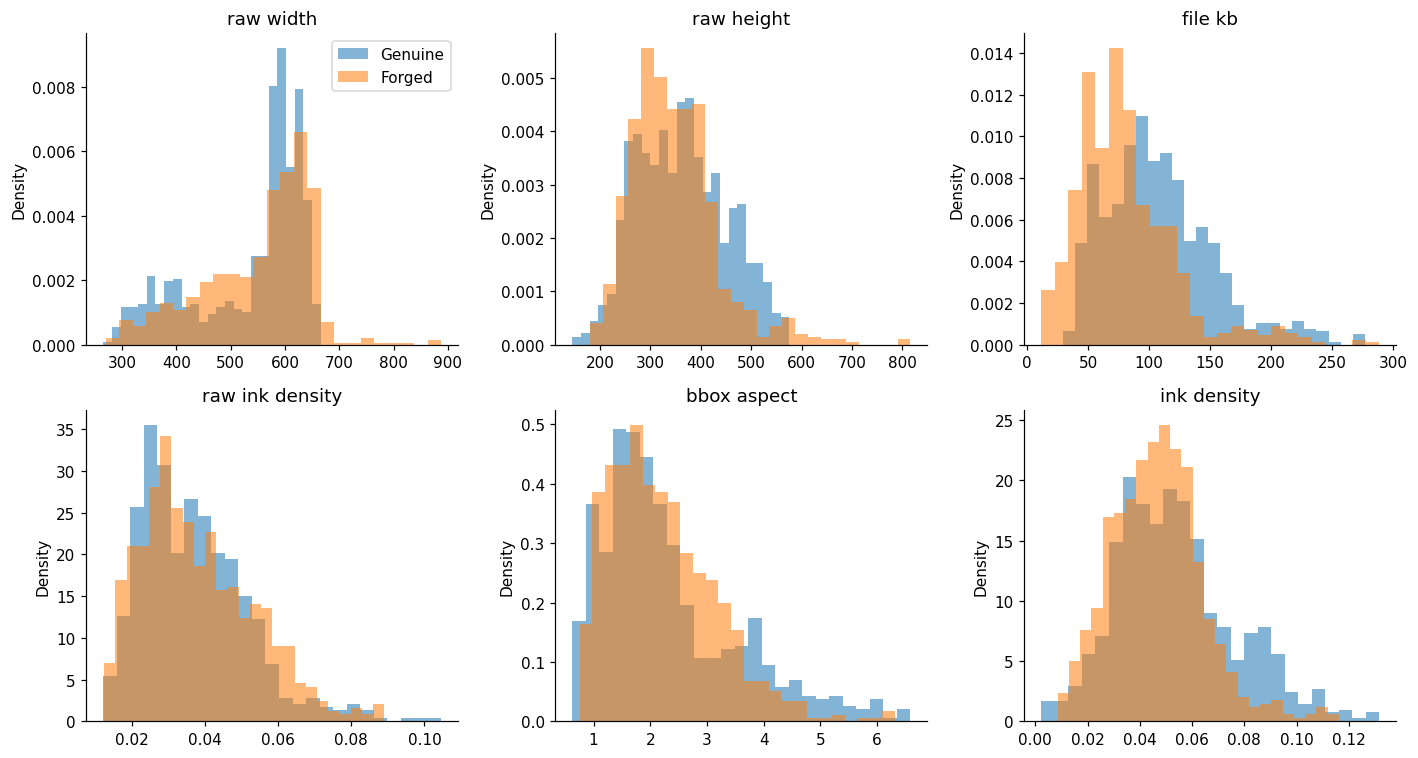

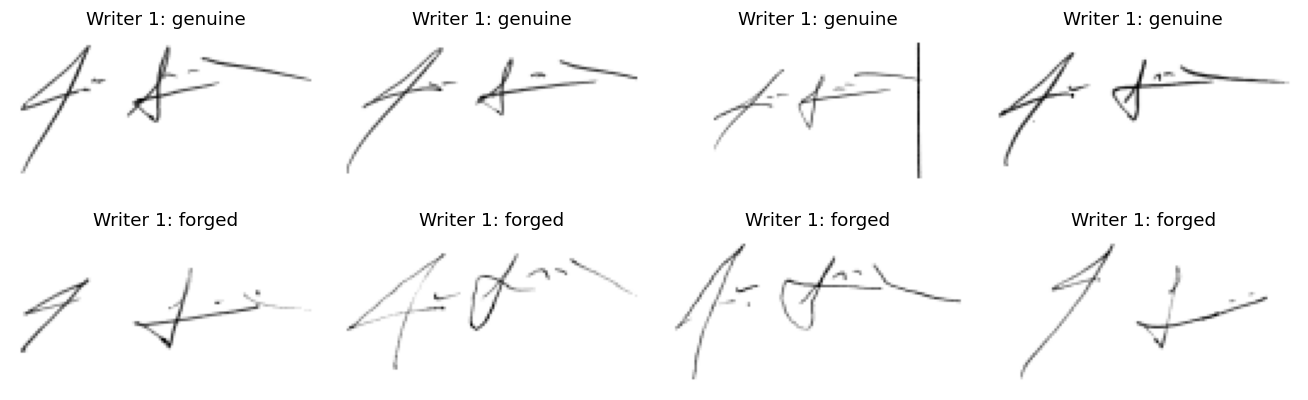

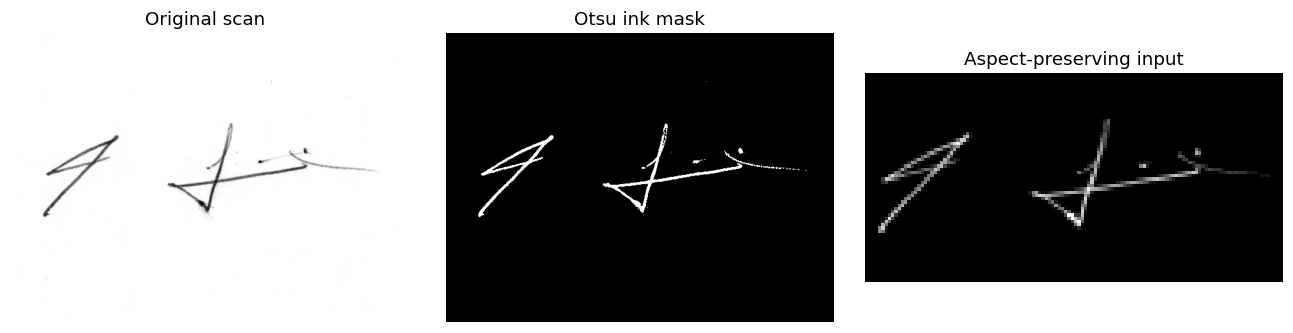

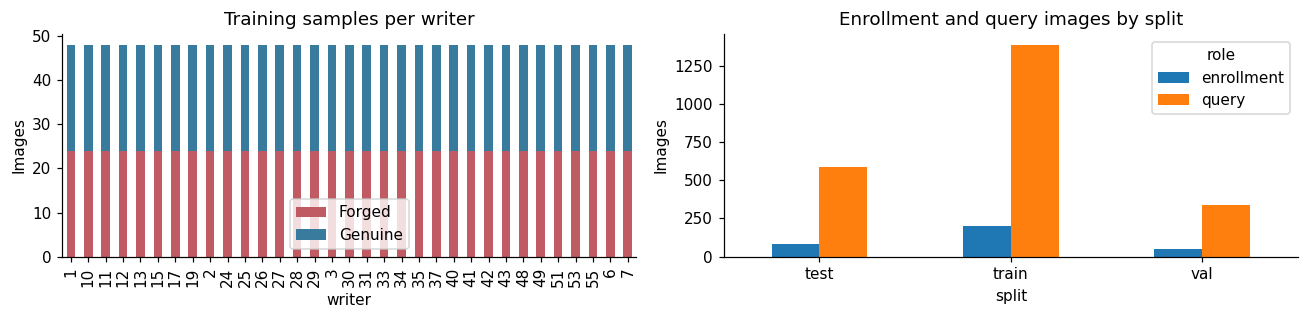

In [5]:
train_manifest=manifest[manifest.split=='train']
fig,axs=plt.subplots(2,3,figsize=(13,7))
for ax,col in zip(axs.flat,['raw_width','raw_height','file_kb','raw_ink_density','bbox_aspect','ink_density']):
    for label,name in [(1,'Genuine'),(0,'Forged')]:
        ax.hist(train_manifest.loc[train_manifest.label==label,col],bins=25,alpha=.55,density=True,label=name)
    ax.set_title(col.replace('_',' ')); ax.set_ylabel('Density')
axs.flat[0].legend(); save_figure(fig,'eda_acquisition')
fig,axs=plt.subplots(2,4,figsize=(12,4))
w=sorted(train_manifest.writer.unique())[0]
for i,label in enumerate([1,0]):
    for ax,row in zip(axs[i],train_manifest[(train_manifest.writer==w)&(train_manifest.label==label)].head(4).itertuples()):
        ax.imshow(images[row.image_id],cmap='gray_r'); ax.axis('off'); ax.set_title(f'Writer {w}: '+('genuine' if label else 'forged'))
save_figure(fig,'signature_examples')
fig,axs=plt.subplots(1,3,figsize=(12,3))
example=train_manifest.iloc[0]
raw=cv2.imread(str(BASE/example.path),cv2.IMREAD_GRAYSCALE)
_,mask=cv2.threshold(raw,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
for ax,img,title in zip(axs,[raw,mask,images[example.image_id]],['Original scan','Otsu ink mask','Aspect-preserving input']):
    ax.imshow(img,cmap='gray'); ax.set_title(title); ax.axis('off')
save_figure(fig,'preprocessing')
fig,axs=plt.subplots(1,2,figsize=(12,3))
train_manifest.groupby(['writer','label']).size().unstack().plot.bar(stacked=True,ax=axs[0],color=['#c05a63','#387b9c'])
axs[0].set_title('Training samples per writer'); axs[0].set_ylabel('Images'); axs[0].legend(['Forged','Genuine'])
manifest.groupby(['split','role']).size().unstack().plot.bar(ax=axs[1],rot=0)
axs[1].set_title('Enrollment and query images by split'); axs[1].set_ylabel('Images')
save_figure(fig,'dataset_counts')


## 4. Cached geometry and HOG; validation-only hyperparameter search

A supervised geometric verifier learns which shape differences distinguish natural variation from forgeries. HOG uses absolute descriptor differences plus cosine/L1/L2 distances and an RBF SVM. Compact C/gamma grids are selected by **validation query ROC-AUC**. Scaling is fit on training pairs only. The optional fourth method is an Extra Trees classifier combining both feature sets.


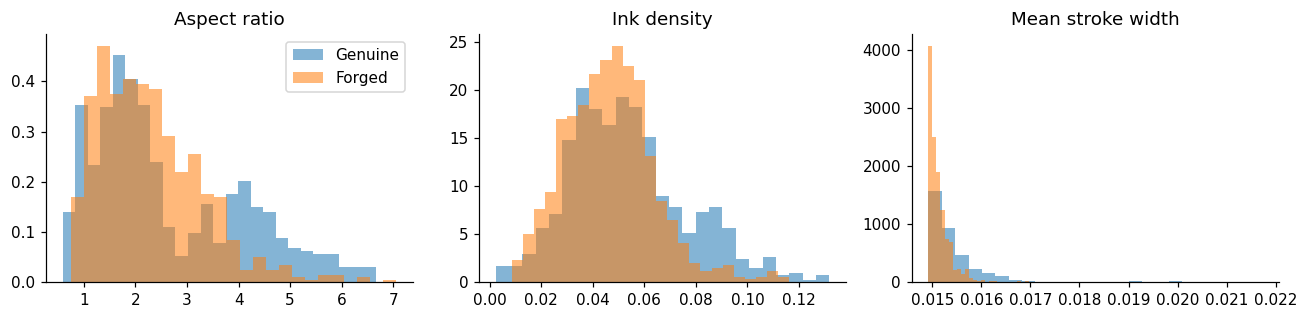

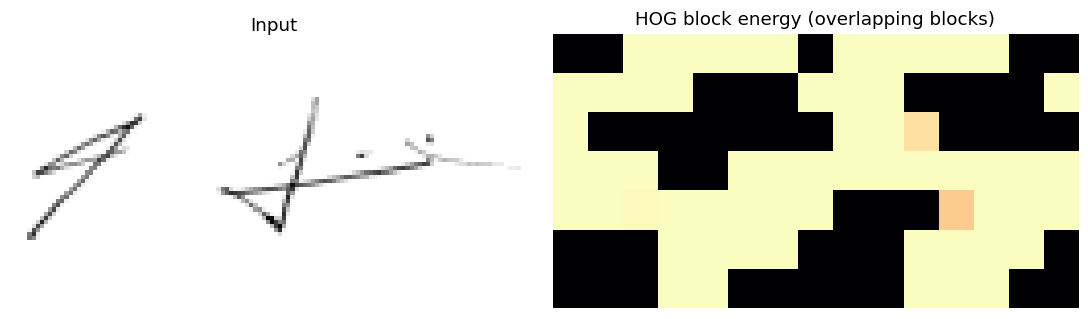

Geometric: C=1, gamma=scale, validation AUC=0.8641
Geometric: C=1, gamma=0.01, validation AUC=0.8730
Geometric: C=10, gamma=scale, validation AUC=0.8437
Geometric: C=10, gamma=0.01, validation AUC=0.8690
Geometric: C=100, gamma=scale, validation AUC=0.8466
Geometric: C=100, gamma=0.01, validation AUC=0.8692
HOG + SVM: C=1, gamma=scale, validation AUC=0.7900
HOG + SVM: C=1, gamma=0.001, validation AUC=0.7815
HOG + SVM: C=10, gamma=scale, validation AUC=0.7846
HOG + SVM: C=10, gamma=0.001, validation AUC=0.7831
HOG + SVM: C=100, gamma=scale, validation AUC=0.7846
HOG + SVM: C=100, gamma=0.001, validation AUC=0.7831


,method,C,gamma,val_ROC_AUC,seconds
0,Geometric,1,scale,0.864113,8.311384
1,Geometric,1,0.01,0.873047,12.437360
2,Geometric,10,scale,0.843750,7.984730
3,Geometric,10,0.01,0.868996,18.201875
4,Geometric,100,scale,0.846644,9.622679
5,Geometric,100,0.01,0.869213,13.823616
6,HOG + SVM,1,scale,0.790003,151.429683
7,HOG + SVM,1,0.001,0.781539,247.630399
8,HOG + SVM,10,scale,0.784614,170.569826
9,HOG + SVM,10,0.001,0.783095,257.457436


In [6]:
geometric=np.stack([geometric_features(im) for im in images])
hog_features=np.stack([HOG.compute(im).ravel() for im in images])
Xgeo={s:pair_features(geometric,p,relative=True) for s,p in pairs.items()}
Xhog={s:pair_features(hog_features,p) for s,p in pairs.items()}
ytrain=pairs['train'].label.to_numpy()
fig,axs=plt.subplots(1,3,figsize=(12,3))
for ax,col,title in zip(axs,[0,1,11],['Aspect ratio','Ink density','Mean stroke width']):
    for label,name in [(1,'Genuine'),(0,'Forged')]:
        ids=train_manifest.loc[train_manifest.label==label,'image_id']
        ax.hist(geometric[ids,col],bins=25,alpha=.55,density=True,label=name)
    ax.set_title(title)
axs[0].legend(); save_figure(fig,'geometric_distributions')
# Visualize HOG block energy on the 7 x 15 descriptor grid.
blocks=hog_features[int(example.image_id)].reshape(7,15,4,9)
energy=np.linalg.norm(blocks,axis=(2,3))
fig,axs=plt.subplots(1,2,figsize=(10,3)); axs[0].imshow(images[int(example.image_id)],cmap='gray_r'); axs[0].set_title('Input')
axs[1].imshow(energy,cmap='magma',aspect='auto'); axs[1].set_title('HOG block energy (overlapping blocks)')
for ax in axs: ax.axis('off')
save_figure(fig,'hog_visualization')

models={}; val_tables={}; search_rows=[]
for name,X in [('Geometric',Xgeo),('HOG + SVM',Xhog)]:
    model_file=OUT/(name.replace(' ','_').replace('+','plus')+'.joblib')
    if not RETRAIN and model_file.exists():
        model=joblib.load(model_file)
    else:
        best_auc=-np.inf; model=None
        for C in [1,10,100]:
            for gamma in ['scale', .01] if name=='Geometric' else ['scale', .001]:
                started=time.perf_counter()
                candidate=make_pipeline(StandardScaler(),SVC(C=C,gamma=gamma,kernel='rbf',class_weight='balanced',cache_size=512))
                candidate.fit(X['train'],ytrain)
                table=aggregate_scores(pairs['val'],candidate.decision_function(X['val']))
                auc=metrics.roc_auc_score(table.label,table.score)
                search_rows.append(dict(method=name,C=C,gamma=gamma,val_ROC_AUC=auc,seconds=time.perf_counter()-started))
                print(f'{name}: C={C}, gamma={gamma}, validation AUC={auc:.4f}',flush=True)
                if auc>best_auc: best_auc=auc; model=candidate
        joblib.dump(model,model_file)
    models[name]=model
    val_tables[name]=aggregate_scores(pairs['val'],model.decision_function(X['val']))
if search_rows: pd.DataFrame(search_rows).to_csv(OUT/'hyperparameter_search.csv',index=False)
display(pd.read_csv(OUT/'hyperparameter_search.csv') if (OUT/'hyperparameter_search.csv').exists() else 'Loaded stored models')

# Optional fourth method: complementary geometry and HOG, without another neural architecture.
Xfusion={s:np.concatenate((Xgeo[s],Xhog[s]),axis=1) for s in pairs}
fusion_file=OUT/'fusion_extra_trees.joblib'
if not RETRAIN and fusion_file.exists(): fusion=joblib.load(fusion_file)
else:
    fusion=ExtraTreesClassifier(n_estimators=300,min_samples_leaf=2,max_features='sqrt',class_weight='balanced',n_jobs=4,random_state=SEED)
    fusion.fit(Xfusion['train'],ytrain); joblib.dump(fusion,fusion_file)
models['Fusion Extra Trees']=fusion
val_tables['Fusion Extra Trees']=aggregate_scores(pairs['val'],fusion.predict_proba(Xfusion['val'])[:,1])


## 5. Train the Siamese CNN

Each epoch reshuffles pairs and independently augments the two signatures. Training uses weighted BCE logits. The checkpoint with the highest **validation query ROC-AUC** is restored; the threshold is selected afterwards on validation. Test labels are not used here.


Epoch 01: loss=0.5333, val AUC=0.8155, val HTER=0.2561, 56.9s
Epoch 02: loss=0.2402, val AUC=0.8184, val HTER=0.2500, 55.7s
Epoch 03: loss=0.1286, val AUC=0.8141, val HTER=0.2648, 53.0s
Epoch 04: loss=0.0674, val AUC=0.8116, val HTER=0.2561, 52.3s
Epoch 05: loss=0.0501, val AUC=0.8140, val HTER=0.2856, 49.0s
Epoch 06: loss=0.0364, val AUC=0.8064, val HTER=0.2917, 56.6s
Epoch 07: loss=0.0120, val AUC=0.8311, val HTER=0.2561, 59.4s
Epoch 08: loss=0.0096, val AUC=0.8331, val HTER=0.2708, 50.3s
Epoch 09: loss=0.0083, val AUC=0.8328, val HTER=0.2648, 50.1s
Epoch 10: loss=0.0087, val AUC=0.8316, val HTER=0.2769, 48.8s
Epoch 11: loss=0.0084, val AUC=0.8428, val HTER=0.2708, 49.8s
Epoch 12: loss=0.0083, val AUC=0.8387, val HTER=0.2769, 55.9s
Epoch 13: loss=0.0032, val AUC=0.8329, val HTER=0.2769, 52.0s
Epoch 14: loss=0.0029, val AUC=0.8303, val HTER=0.2795, 85.9s
Epoch 15: loss=0.0019, val AUC=0.8423, val HTER=0.2561, 74.4s
Epoch 16: loss=0.0023, val AUC=0.8309, val HTER=0.2795, 52.5s
Epoch 17

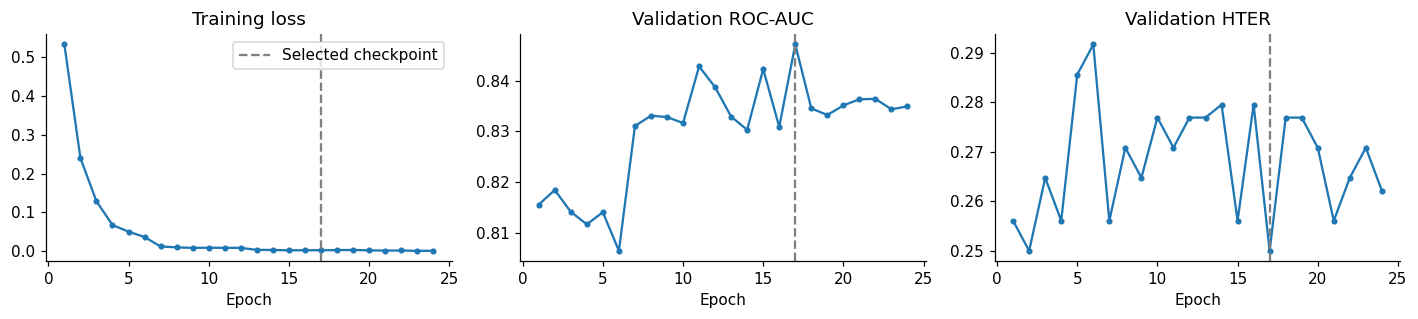

In [7]:
torch.manual_seed(SEED)
cnn=SiameseNet().to(DEVICE)
checkpoint_file=OUT/'siamese_best.pt'
tr_ids=pairs['train'][['ri','qi']].to_numpy(dtype=np.int64)
va_ids=pairs['val'][['ri','qi']].to_numpy(dtype=np.int64)
labels=torch.tensor(ytrain,dtype=torch.float32)
history=[]
if not RETRAIN and checkpoint_file.exists():
    checkpoint=torch.load(checkpoint_file,map_location=DEVICE,weights_only=True)
    cnn.load_state_dict(checkpoint['state_dict'])
    history=pd.read_csv(OUT/'cnn_history.csv').to_dict('records')
    print('Loaded best validation checkpoint, epoch',checkpoint['epoch'])
else:
    optimizer=torch.optim.AdamW(cnn.parameters(),lr=.001,weight_decay=.0001)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='max',factor=.5,patience=3)
    loss_fn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor((ytrain==0).sum()/(ytrain==1).sum(),device=DEVICE))
    best_auc=-np.inf; stale=0
    for epoch in range(1,MAX_EPOCHS+1):
        start=time.perf_counter(); cnn.train(); loss_sum=0
        for idx in torch.randperm(len(labels)).split(BATCH_SIZE):
            pair=tr_ids[idx.numpy()]
            a=augment_batch(image_tensor[pair[:,0]].to(DEVICE))
            b=augment_batch(image_tensor[pair[:,1]].to(DEVICE))
            optimizer.zero_grad(set_to_none=True)
            logits=cnn(a,b); loss=loss_fn(logits,labels[idx].to(DEVICE))
            loss.backward(); nn.utils.clip_grad_norm_(cnn.parameters(),5.); optimizer.step()
            loss_sum+=float(loss.detach())*len(idx)
        va=aggregate_scores(pairs['val'],cnn_scores(cnn,image_tensor,va_ids,device=DEVICE))
        auc=metrics.roc_auc_score(va.label,va.score)
        threshold=select_threshold(va.label,va.score)
        vm=evaluate(va.label,va.score,threshold)
        history.append(dict(epoch=epoch,train_loss=loss_sum/len(labels),val_ROC_AUC=auc,
            val_balanced_accuracy=vm['balanced_accuracy'],val_HTER=vm['HTER'],lr=optimizer.param_groups[0]['lr'],seconds=time.perf_counter()-start))
        pd.DataFrame(history).to_csv(OUT/'cnn_history.csv',index=False)
        print(f'Epoch {epoch:02d}: loss={history[-1]["train_loss"]:.4f}, val AUC={auc:.4f}, val HTER={vm["HTER"]:.4f}, {history[-1]["seconds"]:.1f}s',flush=True)
        scheduler.step(auc)
        if auc>best_auc+1e-4:
            best_auc=auc; stale=0
            torch.save(dict(state_dict={k:v.detach().cpu().clone() for k,v in cnn.state_dict().items()},epoch=epoch,val_ROC_AUC=float(auc)),checkpoint_file)
        else: stale+=1
        if stale>=PATIENCE:
            print('Early stop; restore best validation checkpoint.',flush=True); break
    checkpoint=torch.load(checkpoint_file,map_location=DEVICE,weights_only=True)
    cnn.load_state_dict(checkpoint['state_dict'])
models['Siamese CNN']=cnn
val_tables['Siamese CNN']=aggregate_scores(pairs['val'],cnn_scores(cnn,image_tensor,va_ids,device=DEVICE))
fig,axs=plt.subplots(1,3,figsize=(13,3)); hist=pd.DataFrame(history)
for ax,col,title in zip(axs,['train_loss','val_ROC_AUC','val_HTER'],['Training loss','Validation ROC-AUC','Validation HTER']):
    ax.plot(hist.epoch,hist[col],marker='.'); ax.axvline(checkpoint['epoch'],ls='--',color='gray',label='Selected checkpoint'); ax.set(xlabel='Epoch',title=title)
axs[0].legend(); save_figure(fig,'cnn_learning_curves')


## 6. Freeze selection, then evaluate unseen test writers

The operating threshold approximately balances validation FAR and FRR. Test ROC-EER summarizes the test curve; **it is not a test-selected operating threshold**. Confidence intervals resample writers (clusters), not correlated pairs. Single-reference scores are a matched ablation with their own validation threshold; six-reference aggregation is the primary protocol.

Higher is better: accuracy, balanced accuracy, precision, recall, F1, MCC, AUC and AP. Lower is better: FAR, FRR, HTER and EER. Forged-class recall measures detected forgeries.


In [8]:
def writer_bootstrap(table,threshold,n_boot=500,seed=0):
    rng=np.random.default_rng(seed)
    writers=table.writer.unique(); groups={w:table[table.writer==w] for w in writers}
    values=[]
    for _ in range(n_boot):
        sample=pd.concat([groups[w] for w in rng.choice(writers,len(writers),replace=True)],ignore_index=True)
        y=sample.label.to_numpy(); score=sample.score.to_numpy(); pred=score>=threshold
        far=pred[y==0].mean(); frr=(~pred[y==1]).mean()
        values.append(dict(accuracy=(pred==y).mean(),balanced_accuracy=1-(far+frr)/2,
            FAR=far,FRR=frr,ROC_AUC=metrics.roc_auc_score(y,score),
            forged_F1=metrics.f1_score(y,pred,pos_label=0,zero_division=0)))
    frame=pd.DataFrame(values)
    return pd.DataFrame({'lower_95':frame.quantile(.025),'upper_95':frame.quantile(.975)})


In [9]:
method_order=['Geometric','HOG + SVM','Siamese CNN','Fusion Extra Trees']
thresholds={name:select_threshold(val_tables[name].label,val_tables[name].score) for name in method_order}
selected=dict(thresholds=thresholds,cnn_epoch=checkpoint['epoch'],cnn_val_ROC_AUC=checkpoint['val_ROC_AUC'],
    sklearn_parameters={name: {'C':models[name][-1].C,'gamma':models[name][-1].gamma} for name in ['Geometric','HOG + SVM']},
    selection='validation query ROC-AUC; thresholds validation equal-error approximation')
(OUT/'selected_models.json').write_text(json.dumps(selected,indent=2))
print('Selections frozen before test scoring:',selected)

score_pairs={
    'Geometric':models['Geometric'].decision_function(Xgeo['test']),
    'HOG + SVM':models['HOG + SVM'].decision_function(Xhog['test']),
    'Siamese CNN':cnn_scores(cnn,image_tensor,pairs['test'][['ri','qi']].to_numpy(),device=DEVICE),
    'Fusion Extra Trees':fusion.predict_proba(Xfusion['test'])[:,1]}
test_tables={name:aggregate_scores(pairs['test'],sc) for name,sc in score_pairs.items()}
results=[]; ci_rows=[]; predictions=[]
for name in method_order:
    table=test_tables[name]; threshold=thresholds[name]
    row={'method':name,**evaluate(table.label,table.score,threshold)}; results.append(row)
    table=table.copy(); table['method']=name; table['threshold']=threshold; table['prediction']=(table.score>=threshold).astype(int)
    predictions.append(table)
    ci=writer_bootstrap(table,threshold,seed=SEED).reset_index(names='metric'); ci['method']=name; ci_rows.append(ci)
metrics_table=pd.DataFrame(results).set_index('method')
metrics_table.to_csv(OUT/'metrics.csv')
pd.concat(predictions,ignore_index=True).to_csv(OUT/'predictions.csv',index=False)
intervals=pd.concat(ci_rows,ignore_index=True); intervals.to_csv(OUT/'confidence_intervals.csv',index=False)
display(metrics_table[['accuracy','balanced_accuracy','forged_F1','ROC_AUC','forged_AP','FAR','FRR','ROC_EER']].round(4))

# Matched single-reference ablation: use the first enrollment reference consistently.
ablation=[]
for name in method_order:
    va_pair=(models[name].decision_function(Xgeo['val']) if name=='Geometric' else
        models[name].decision_function(Xhog['val']) if name=='HOG + SVM' else
        cnn_scores(cnn,image_tensor,va_ids,device=DEVICE) if name=='Siamese CNN' else
        fusion.predict_proba(Xfusion['val'])[:,1])
    keep_val=~pairs['val'].query.duplicated() if False else ~pairs['val']['query'].duplicated()
    keep_test=~pairs['test']['query'].duplicated()
    va=aggregate_scores(pairs['val'][keep_val],va_pair[keep_val])
    te=aggregate_scores(pairs['test'][keep_test],score_pairs[name][keep_test])
    t=select_threshold(va.label,va.score)
    ablation.append({'method':name,'references':1,**evaluate(te.label,te.score,t)})
    ablation.append({'method':name,'references':N_REFS,**evaluate(test_tables[name].label,test_tables[name].score,thresholds[name])})
ablation=pd.DataFrame(ablation); ablation.to_csv(OUT/'reference_ablation.csv',index=False)
display(ablation[['method','references','accuracy','balanced_accuracy','FAR','FRR']].round(4))


Selections frozen before test scoring: {'thresholds': {'Geometric': -0.16028927621674607, 'HOG + SVM': -0.35495863162384206, 'Siamese CNN': -3.6722867488861084, 'Fusion Extra Trees': 0.37350216450216456}, 'cnn_epoch': 17, 'cnn_val_ROC_AUC': 0.8471498842592593, 'sklearn_parameters': {'Geometric': {'C': 1, 'gamma': 0.01}, 'HOG + SVM': {'C': 1, 'gamma': 'scale'}}, 'selection': 'validation query ROC-AUC; thresholds validation equal-error approximation'}


,accuracy,balanced_accuracy,forged_F1,ROC_AUC,forged_AP,FAR,FRR,ROC_EER
method,,,,,,,,
Geometric,0.8044,0.8046,0.8244,0.8833,0.9070,0.1964,0.1944,0.1944
HOG + SVM,0.8231,0.8224,0.8424,0.8903,0.9064,0.1726,0.1825,0.1786
Siamese CNN,0.7823,0.7649,0.8232,0.8711,0.8865,0.1131,0.3571,0.1935
Fusion Extra Trees,0.8503,0.8492,0.8675,0.9248,0.9488,0.1429,0.1587,0.1508


,method,references,accuracy,balanced_accuracy,FAR,FRR
0,Geometric,1,0.7194,0.7138,0.2470,0.3254
1,Geometric,6,0.8044,0.8046,0.1964,0.1944
2,HOG + SVM,1,0.7109,0.7138,0.3065,0.2659
3,HOG + SVM,6,0.8231,0.8224,0.1726,0.1825
4,Siamese CNN,1,0.7670,0.7560,0.1667,0.3214
5,Siamese CNN,6,0.7823,0.7649,0.1131,0.3571
6,Fusion Extra Trees,1,0.7432,0.7490,0.2917,0.2103
7,Fusion Extra Trees,6,0.8503,0.8492,0.1429,0.1587


## 7. Evaluation figures and error analysis


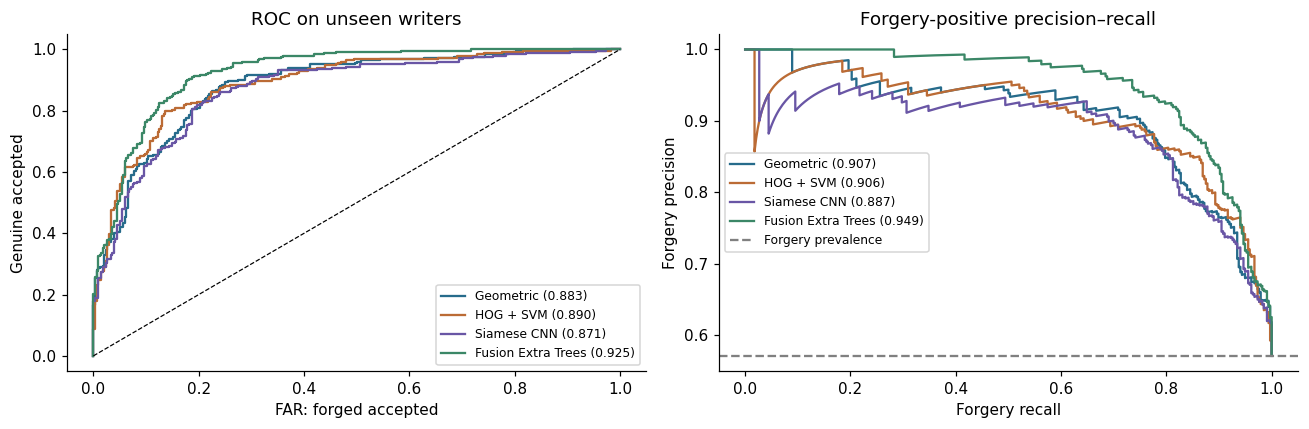

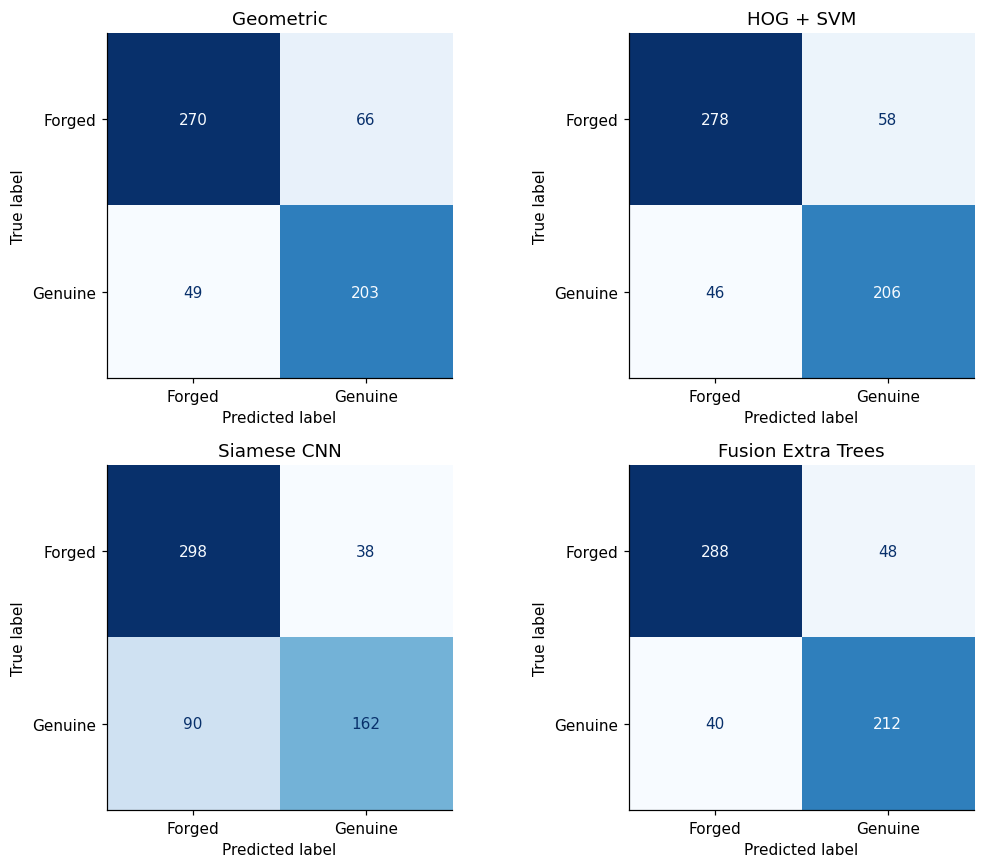

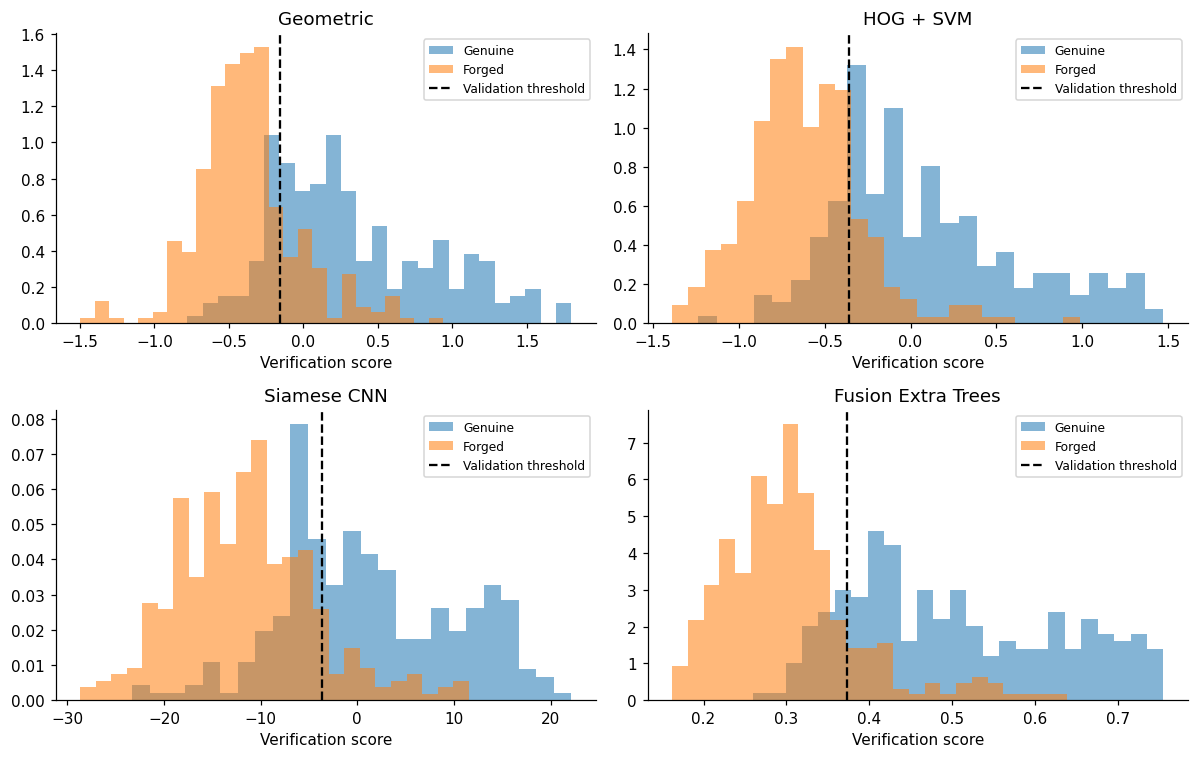

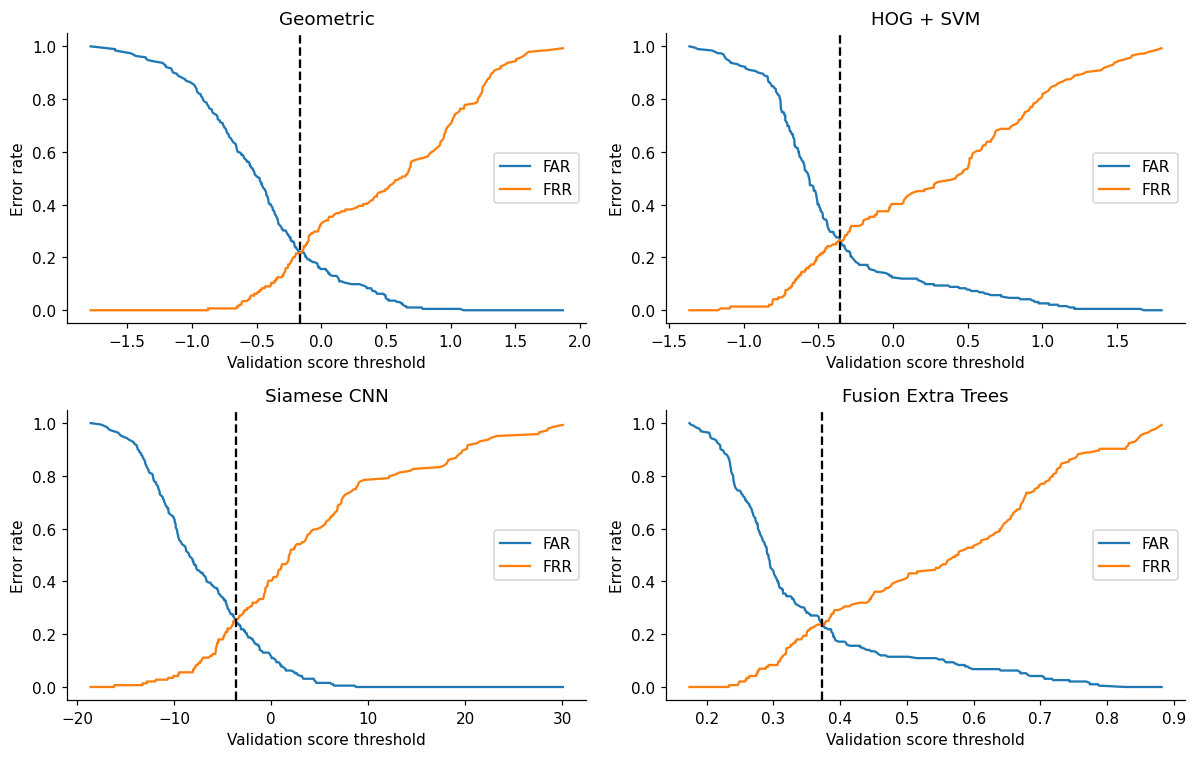

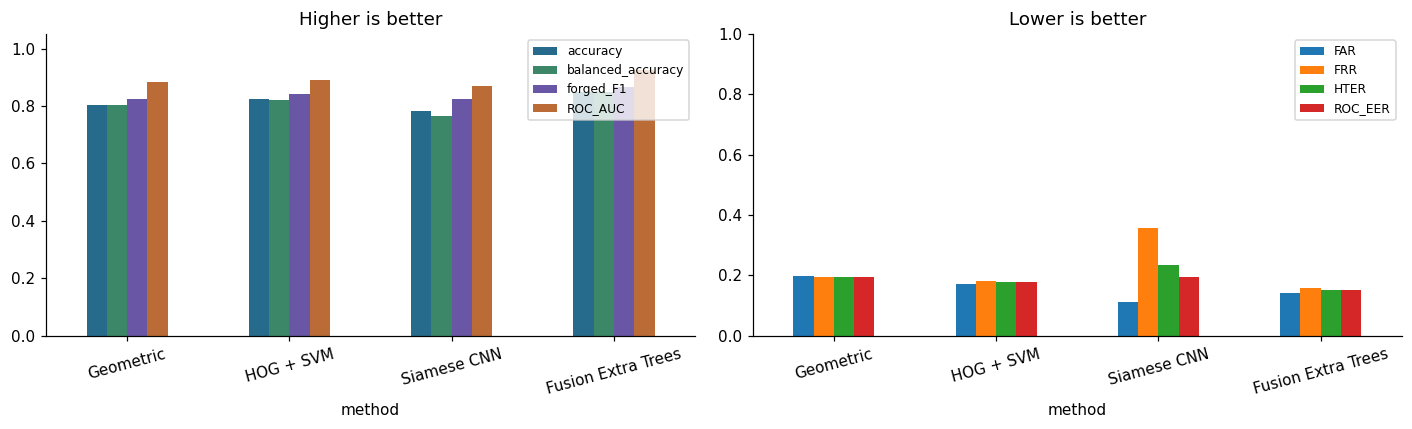

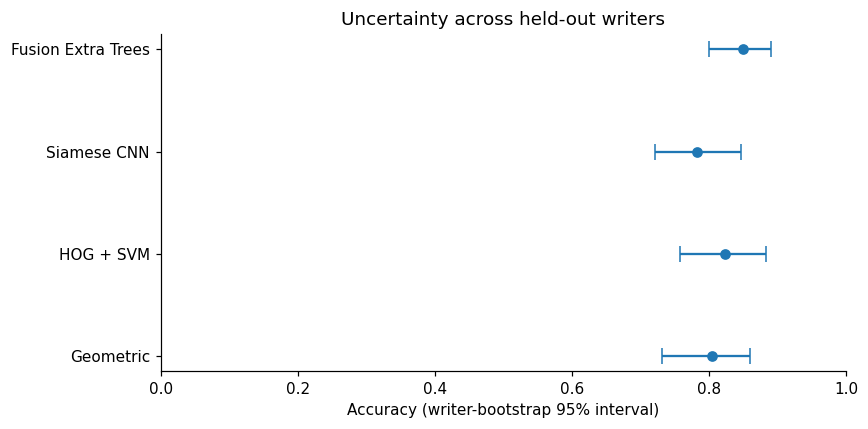

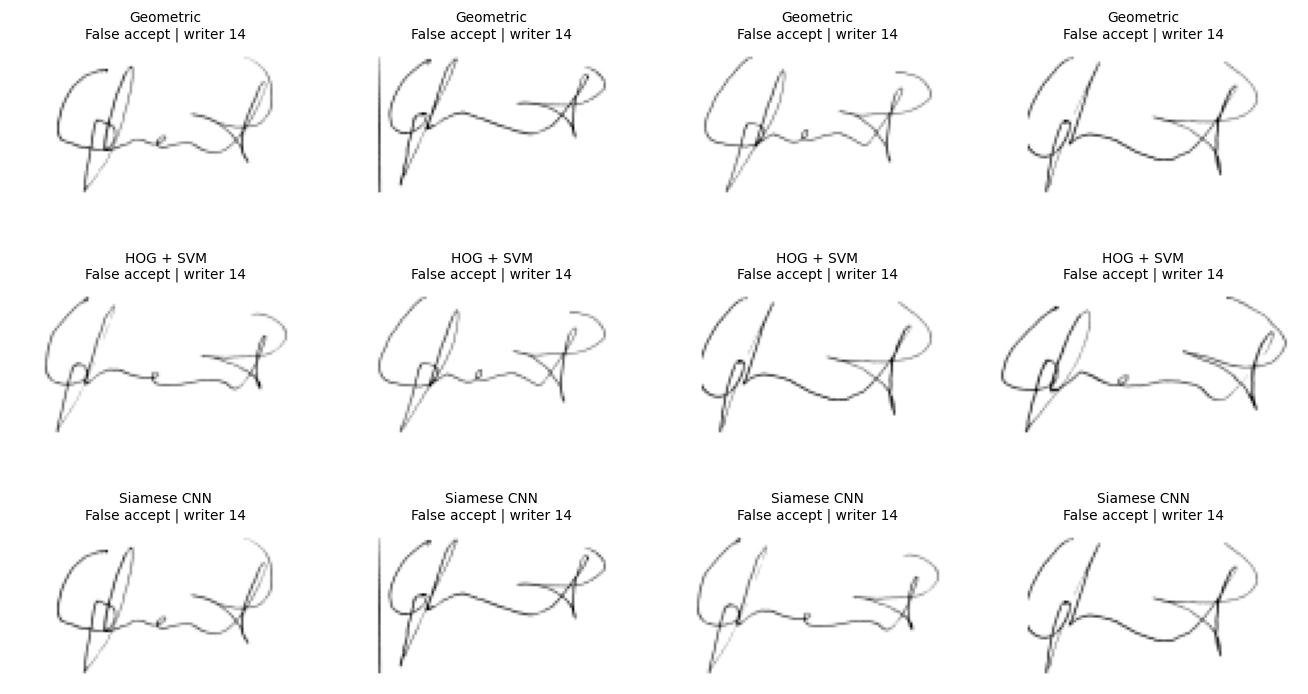

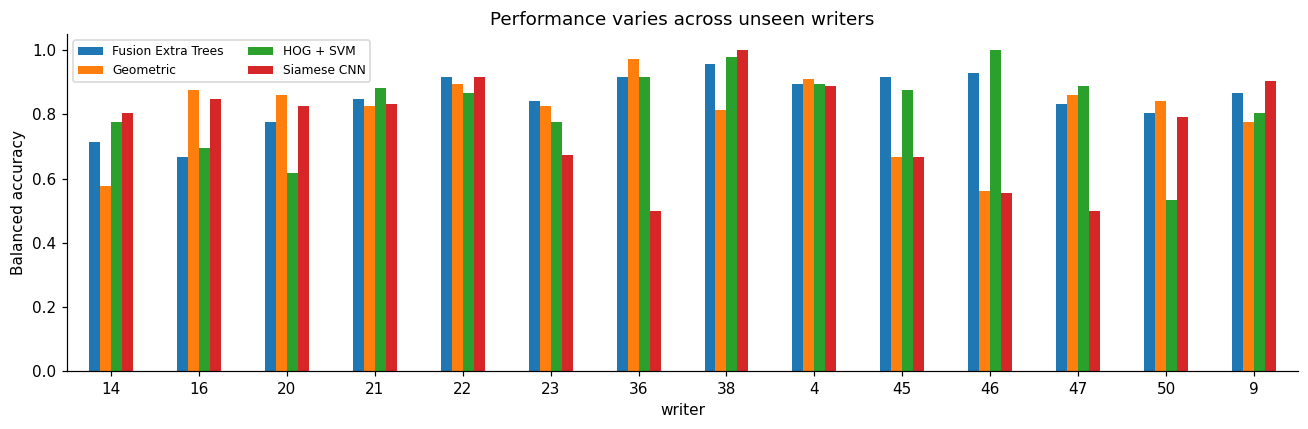

In [10]:
colors=['#266b8b','#bb6b35','#6956a5','#3b8767']
fig,axs=plt.subplots(1,2,figsize=(12,4))
for name,color in zip(method_order,colors):
    table=test_tables[name]
    far,gar,_=metrics.roc_curve(table.label,table.score)
    axs[0].plot(far,gar,label=f'{name} ({metrics_table.loc[name,"ROC_AUC"]:.3f})',color=color)
    precision,recall,_=metrics.precision_recall_curve(1-table.label,-table.score)
    axs[1].plot(recall,precision,label=f'{name} ({metrics_table.loc[name,"forged_AP"]:.3f})',color=color)
axs[0].plot([0,1],[0,1],'k--',lw=.8); axs[0].set(xlabel='FAR: forged accepted',ylabel='Genuine accepted',title='ROC on unseen writers')
axs[1].axhline((test_tables['Geometric'].label==0).mean(),ls='--',color='gray',label='Forgery prevalence')
axs[1].set(xlabel='Forgery recall',ylabel='Forgery precision',title='Forgery-positive precision–recall')
for ax in axs: ax.legend(fontsize=8)
save_figure(fig,'roc_and_precision_recall')
fig,axs=plt.subplots(2,2,figsize=(10,8))
for ax,name in zip(axs.flat,method_order):
    table=test_tables[name]; pred=table.score>=thresholds[name]
    metrics.ConfusionMatrixDisplay.from_predictions(table.label,pred,labels=[0,1],display_labels=['Forged','Genuine'],ax=ax,colorbar=False,cmap='Blues')
    ax.set_title(name)
save_figure(fig,'confusion_matrices')
fig,axs=plt.subplots(2,2,figsize=(11,7))
for ax,name in zip(axs.flat,method_order):
    table=test_tables[name]
    for label,text in [(1,'Genuine'),(0,'Forged')]:
        ax.hist(table.loc[table.label==label,'score'],bins=25,alpha=.55,density=True,label=text)
    ax.axvline(thresholds[name],color='black',ls='--',label='Validation threshold'); ax.set_title(name); ax.set_xlabel('Verification score'); ax.legend(fontsize=8)
save_figure(fig,'test_score_distributions')
fig,axs=plt.subplots(2,2,figsize=(11,7))
for ax,name in zip(axs.flat,method_order):
    table=val_tables[name]; far,gar,ts=metrics.roc_curve(table.label,table.score,drop_intermediate=False)
    valid=np.isfinite(ts); ax.plot(ts[valid],far[valid],label='FAR'); ax.plot(ts[valid],1-gar[valid],label='FRR')
    ax.axvline(thresholds[name],color='black',ls='--'); ax.set(title=name,xlabel='Validation score threshold',ylabel='Error rate'); ax.legend()
save_figure(fig,'validation_threshold_tradeoffs')
fig,axs=plt.subplots(1,2,figsize=(13,4))
metrics_table.loc[method_order,['accuracy','balanced_accuracy','forged_F1','ROC_AUC']].plot.bar(ax=axs[0],rot=15,color=['#266b8b','#3b8767','#6956a5','#bb6b35'])
axs[0].set(ylim=(0,1.05),title='Higher is better'); axs[0].legend(fontsize=8)
metrics_table.loc[method_order,['FAR','FRR','HTER','ROC_EER']].plot.bar(ax=axs[1],rot=15)
axs[1].set(ylim=(0,1),title='Lower is better'); axs[1].legend(fontsize=8)
save_figure(fig,'metric_comparison')
fig,ax=plt.subplots(figsize=(8,4))
ci=intervals[intervals.metric=='accuracy'].set_index('method').loc[method_order]
v=metrics_table.loc[method_order,'accuracy']
ax.errorbar(v,np.arange(len(v)),xerr=[np.maximum(0,v-ci.lower_95),np.maximum(0,ci.upper_95-v)],fmt='o',capsize=5)
ax.set(yticks=np.arange(len(v)),yticklabels=method_order,xlabel='Accuracy (writer-bootstrap 95% interval)',xlim=(0,1),title='Uncertainty across held-out writers')
save_figure(fig,'accuracy_confidence_intervals')
# Show false accepts/rejects for every required model; errors are examples, not a new tuning set.
fig,axs=plt.subplots(3,4,figsize=(12,7))
lookup=manifest.set_index('path')
for row_idx,name in enumerate(method_order[:3]):
    table=test_tables[name]; pred=table.score>=thresholds[name]
    errors=table[pred!=table.label.astype(bool)]
    for col,ax in enumerate(axs[row_idx]):
        ax.axis('off')
        if col<len(errors):
            q=errors.iloc[col]; ax.imshow(images[int(lookup.loc[q['query'],'image_id'])],cmap='gray_r')
            ax.set_title(name+'\n'+('False accept' if q.label==0 else 'False reject')+f' | writer {q.writer}',fontsize=9)
        else: ax.set_title(name+'\nNo further errors',fontsize=9)
save_figure(fig,'error_examples')

per_writer=[]
for name,table in test_tables.items():
    for writer,group in table.groupby('writer'):
        per_writer.append(dict(method=name,writer=writer,**evaluate(group.label,group.score,thresholds[name])))
per_writer=pd.DataFrame(per_writer); per_writer.to_csv(OUT/'per_writer_metrics.csv',index=False)
fig,ax=plt.subplots(figsize=(12,4))
per_writer.pivot(index='writer',columns='method',values='balanced_accuracy').plot.bar(ax=ax,rot=0)
ax.set(ylim=(0,1.05),title='Performance varies across unseen writers',ylabel='Balanced accuracy')
ax.legend(fontsize=8,ncol=2); save_figure(fig,'per_writer_performance')


## 8. Discussion, limitations and coursework structure

**Historical random-pair results (not rerun here):** Geometric accuracy 0.610, HOG+SVM 0.708, Siamese CNN 0.611. Do not subtract these from the new table and claim a controlled model-only gain: enrollment, preprocessing and score aggregation changed. The single-reference ablation isolates the effect of aggregation under the new protocol, not all training changes.

**Interpretation:** report test accuracy alongside forged recall/F1, FAR, FRR and AUC. A low FAR reduces accepted forgeries; a low FRR reduces rejected genuine signatures. Operating scores are uncalibrated and a validation equal-error threshold is not automatically suitable for a bank.

**Limitations:** only 55 writers from one dataset, one fixed writer split, correlated samples, and eight validation writers. Model selection may overfit these validation writers. Writer bootstrap intervals are conditional on this split. Acquisition artifacts can distinguish the classes. Cross-dataset evaluation and repeated predeclared writer splits are future work; test results must not guide another confirmatory model choice.

**Four-student allocation:** (1) dataset audit, preprocessing and EDA; (2) geometric verifier; (3) HOG+SVM; (4) Siamese CNN. All four jointly review the protocol, comparison and paper.

**Paper outline:** Abstract → Signature verification problem → Related work with verified citations → CEDAR and writer-disjoint protocol → Three approaches → Experimental setup → Tables and figures → Error analysis and limitations → Conclusion. Use the exported metrics and figures, and describe the geometric method as a supervised shape-feature verifier.

**Dataset attribution:** CEDAR copy inherited from this repository; consult its README and the original dataset terms for redistribution. No external training data or pretrained weights are used.
